# Radar: FMCW, Range-Doppler and Micro-Doppler

> **Who is this for:** learners who finished [01 - Signals, frequency and sensor basics](01_signals_frequency_and_sensor_basics.ipynb) (FFT, windowing, spectrograms) and want to understand the radar chips now found in cars, smart-home devices and elder-care sensors. No radio-engineering background is needed.
>
> **What you will learn:**
> - how radar works (send a radio wave, listen for the echo), **frequency and wavelength**, and the common **mmWave** bands
> - **pulse vs FMCW** radar, the **chirp**, and how the **beat frequency** gives **range** (with a simulated multi-target signal and a range FFT)
> - **Doppler** and **velocity** across chirps, and the 2-D FFT **range-Doppler map**
> - **angle of arrival** with several receive antennas, the angle FFT and the **MIMO virtual array** idea
> - **CFAR** detection (we implement CA-CFAR), **clustering** detections into objects with DBSCAN, and a **tracking** teaser
> - **micro-Doppler** signatures of a walking person and of a **fall**, and a scikit-learn classifier on them
> - **vital signs**: measuring breathing from tiny phase changes; plus gesture sensing and in-cabin child presence
> - **radar vs camera vs LiDAR**, and where radar is used in industry
>
> **Prerequisites:** [01 - Signals, frequency and sensor basics](01_signals_frequency_and_sensor_basics.ipynb), [NumPy](../02_Data_Analysis/02_numpy.ipynb). Helpful: [02 - IMU activity recognition and fall detection](02_imu_activity_recognition_and_fall_detection.ipynb) (for the fall-detection metrics), complex numbers (a short reminder is given below).
>
> **Time needed:** about 2-3 hours to read and play (the notebook runs in well under a minute).
>
> **Runs on:** CPU, no API key, no internet. Uses numpy, scipy, scikit-learn and matplotlib. All radar data is **simulated** with simple physics; real radar data has more effects (multipath, interference, antenna patterns), so all numbers are illustrative.

## 0. Setup

**A one-minute reminder on complex numbers.** Radar chips output **complex** samples `I + jQ` (I = "in-phase", Q = "quadrature"). Think of each sample as an arrow with a **length** (amplitude, `np.abs`) and a **direction** (phase angle, `np.angle`). `np.exp(1j * phi)` is an arrow of length 1 pointing at angle `phi`. A signal `exp(j * 2 * pi * f * t)` is an arrow spinning `f` times per second; positive `f` spins one way and negative `f` the other way. That is how radar tells "coming closer" from "moving away".

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, ndimage
from sklearn.cluster import DBSCAN
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix

SEED = 3
rng = np.random.default_rng(SEED)
plt.rcParams["figure.figsize"] = (9, 3); plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=3, suppress=True)
C = 3e8                                   # speed of light in m/s
print("ready")

ready


## 1. How radar works

**What it is.** **Radar** (RAdio Detection And Ranging) sends out a radio wave and listens for the **echo** that bounces back from objects. From the echo it measures:
- **range** (distance), from how long the echo took,
- **radial velocity** (speed towards or away from the radar), from the **Doppler effect**,
- **angle** (direction), by comparing the echo at several antennas.

**Simple analogy.** Shouting in a canyon. The longer the echo takes, the farther the wall. If a train is coming towards you, its horn sounds higher; moving away, lower. That pitch change is the Doppler effect, and radar measures it with radio waves.

**How it works.** The echo travels to the object and back, so with round-trip time `tau`:

`range R = C * tau / 2`

Radio waves travel at the speed of light (`C ≈ 3 x 10^8 m/s`), so an object at 15 m returns its echo after only 100 nanoseconds. Measuring such tiny times directly is hard; FMCW radar (section 3) turns the time into a frequency, which is easy to measure with an FFT.

**How strong is the echo?** The **radar equation** says the received power falls with the **fourth power** of range: `P_received ∝ RCS / R^4`. **RCS (radar cross section)** describes how "radar-bright" an object is, in m². A car is much brighter than a person, and a person is much brighter than a small bird. Doubling the distance makes the echo 16 times weaker.

In [2]:
for name, R in [("person at 5 m", 5), ("car at 50 m", 50), ("truck at 200 m", 200)]:
    print(f"{name:<16} round trip = {2 * R / C * 1e9:8.1f} ns")
print("echo power at 2x the distance:", 1 / 2**4, "of the original")

person at 5 m    round trip =     33.3 ns
car at 50 m      round trip =    333.3 ns
truck at 200 m   round trip =   1333.3 ns
echo power at 2x the distance: 0.0625 of the original


## 2. Frequency, wavelength and mmWave bands

**What it is.** A radio wave's **frequency** `f` is how many times it oscillates per second (Hz; 1 GHz = 10^9 Hz). Its **wavelength** `lambda` is the distance between two wave crests: `lambda = C / f`. **mmWave** (millimetre-wave) means frequencies roughly from 30 to 300 GHz, where wavelengths are a few millimetres.

**Why mmWave is popular for sensing.**
- Short wavelength -> **small antennas**, so a whole radar with many antennas fits on one chip.
- Short wavelength -> tiny motions change the echo's phase a lot, so radar can "feel" **breathing** (section 11).
- Wide bandwidth is available at these frequencies -> fine range resolution (section 4).

Common sensing bands (allocations differ by country, so always check the local rules; this is a general overview as of late 2026):

| Band | Wavelength | Typical uses |
|---|---|---|
| around 24 GHz | about 12.5 mm | older automotive sensors, motion/presence detectors, industrial sensors |
| around 60 GHz (roughly 57-64 GHz, wider in some regions) | about 5 mm | indoor presence, gesture sensing, in-cabin monitoring, vital signs, elder care |
| around 77 GHz (76-81 GHz) | about 3.9 mm | automotive radar: adaptive cruise control, emergency braking, blind-spot detection, imaging radar |

In [3]:
for f_ghz in [24, 60, 77]:
    print(f"{f_ghz} GHz -> wavelength = {C / (f_ghz * 1e9) * 1000:.2f} mm")

24 GHz -> wavelength = 12.50 mm
60 GHz -> wavelength = 5.00 mm
77 GHz -> wavelength = 3.90 mm


## 3. Pulse radar vs FMCW radar

| | **Pulse radar** | **FMCW radar** (Frequency-Modulated Continuous Wave) |
|---|---|---|
| What it sends | short, strong bursts, then listens | a continuous **chirp**: a tone whose frequency rises steadily |
| How it gets range | measures the echo delay directly | mixes echo with the transmitted chirp; the delay becomes a **beat frequency** |
| Hardware | high peak power, very fast timing | low power, slow and cheap ADCs, everything on one chip |
| Typical use | long-range: air traffic control, weather, military | short to medium range: cars, factories, smart homes, phones and wearables |

Almost all modern mmWave sensing chips are FMCW, so the rest of this notebook is about FMCW.

### The FMCW chirp and the beat frequency

**What it is.** A **chirp** is a signal whose frequency rises linearly over time: `f(t) = f_c + S * t`, where `f_c` is the start frequency and `S` is the **slope** (Hz per second). The chirp sweeps a **bandwidth** `B` during time `T`, so `S = B / T`.

**Simple analogy.** Imagine singing a note that rises steadily, like a siren. Your echo comes back a moment later, so it is a slightly *lower* note than the one you are singing *now*. The difference between the two notes tells you how long the echo took. A far wall gives a bigger difference.

**How it works.**
1. The radar transmits the chirp (TX).
2. The echo (RX) is the same chirp, delayed by `tau = 2R / C`.
3. A **mixer** multiplies TX and RX. The output, called the **IF (intermediate frequency) signal**, is a simple tone at the **beat frequency** `f_b = S * tau = 2 * S * R / C`.
4. An FFT of the IF signal gives one peak per object, at `f_b`. Then `R = C * f_b / (2 * S)`.

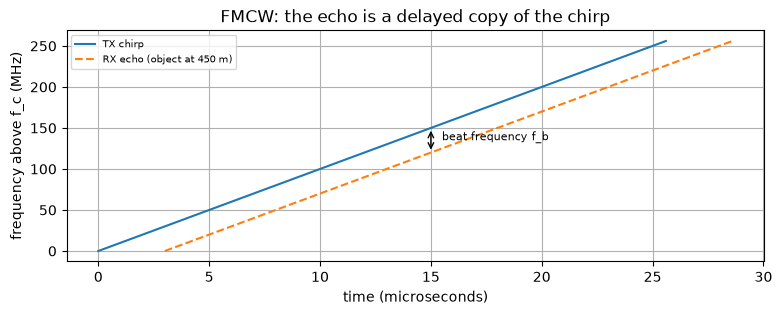

slope S = 10 MHz per microsecond; object at 450 m -> f_b = 30.0 MHz


In [4]:
T_ch, B_ch = 25.6e-6, 256e6                      # chirp duration and bandwidth (example values)
S_ch = B_ch / T_ch                               # slope in Hz per second
t_us = np.linspace(0, T_ch, 200)
R_demo = 450.0                                   # a far object, to make the gap visible in the plot
tau = 2 * R_demo / C
plt.plot(t_us * 1e6, S_ch * t_us / 1e6, label="TX chirp")
plt.plot((t_us + tau) * 1e6, S_ch * t_us / 1e6, "--", label=f"RX echo (object at {R_demo:.0f} m)")
plt.annotate("", xy=(15, S_ch * 15e-6 / 1e6), xytext=(15, S_ch * (15e-6 - tau) / 1e6),
             arrowprops=dict(arrowstyle="<->"))
plt.text(15.5, S_ch * (15e-6 - tau / 2) / 1e6, "beat frequency f_b", fontsize=8)
plt.xlabel("time (microseconds)"); plt.ylabel("frequency above f_c (MHz)"); plt.legend(fontsize=7)
plt.title("FMCW: the echo is a delayed copy of the chirp"); plt.show()
print(f"slope S = {S_ch / 1e12:.0f} MHz per microsecond; object at {R_demo:.0f} m -> f_b = {2 * S_ch * R_demo / C / 1e6:.1f} MHz")

## 4. Range from the IF signal (range FFT)

We now set up a radar similar to a 77 GHz automotive chip (example values, chosen to give round numbers):

| Parameter | Symbol | Value |
|---|---|---|
| start frequency | `f_c` | 77 GHz |
| samples per chirp | `N_s` | 256 |
| ADC sampling rate | `fs` | 10 MHz (complex I/Q samples) |
| sampled chirp time | `N_s / fs` | 25.6 µs |
| slope | `S` | 10 MHz/µs |
| bandwidth swept while sampling | `B = S * N_s / fs` | 256 MHz |

Two key formulas:
- **Range resolution** (closest two objects can be and still be separated): `dR = C / (2 * B)`. More bandwidth = finer resolution.
- **Maximum range** (with complex sampling): `R_max = fs * C / (2 * S)`.

wavelength = 3.90 mm, bandwidth = 256 MHz
range resolution = 0.586 m, max range = 150 m


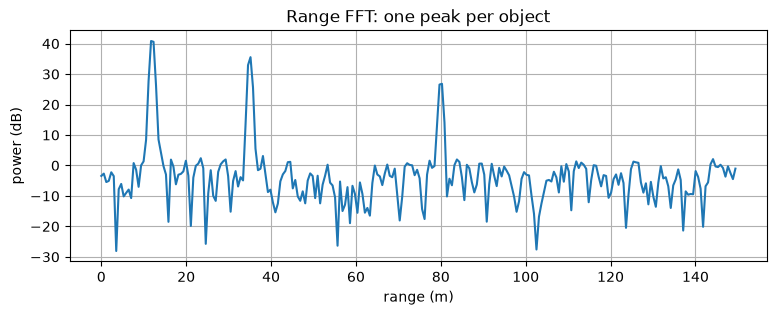

objects found at: [11.72 35.16 80.27] m (true: 12, 35, 80 m)


In [5]:
FC, NS, FS_ADC, SLOPE = 77e9, 256, 10e6, 10e6 / 1e-6
LAM = C / FC                                       # wavelength (m)
B_EFF = SLOPE * NS / FS_ADC
print(f"wavelength = {LAM * 1000:.2f} mm, bandwidth = {B_EFF / 1e6:.0f} MHz")
print(f"range resolution = {C / (2 * B_EFF):.3f} m, max range = {FS_ADC * C / (2 * SLOPE):.0f} m")

def if_signal(targets, slope=SLOPE, noise=0.05):
    """IF samples of one chirp. targets = list of (range_m, amplitude)."""
    n = np.arange(NS)
    x = sum(a * np.exp(2j * np.pi * (2 * slope * R / C) * n / FS_ADC) for R, a in targets)
    return x + noise * (rng.normal(size=NS) + 1j * rng.normal(size=NS))

def range_profile(x, slope=SLOPE):
    spec = np.fft.fft(x * np.hanning(NS))          # the range FFT (with a Hann window)
    # with complex (I/Q) samples all beat frequencies are positive, so bin k <-> k * fs / NS Hz
    ranges = np.arange(NS) * FS_ADC / NS * C / (2 * slope)
    return ranges, 20 * np.log10(np.abs(spec) + 1e-9)

targets = [(12.0, 1.0), (35.0, 0.5), (80.0, 0.2)]          # three objects
r, p = range_profile(if_signal(targets))
plt.plot(r, p); plt.xlabel("range (m)"); plt.ylabel("power (dB)")
plt.title("Range FFT: one peak per object"); plt.show()
peaks, _ = signal.find_peaks(p, height=p.max() - 30, distance=5)
print("objects found at:", r[peaks].round(2), "m (true: 12, 35, 80 m)")

**Range resolution in action.** Two objects 0.5 m apart. With 256 MHz of bandwidth (resolution about 0.59 m) they merge into one peak. With a steeper chirp that sweeps 1 GHz (resolution 0.15 m) they separate. This is why automotive radars want as much bandwidth as the rules allow.

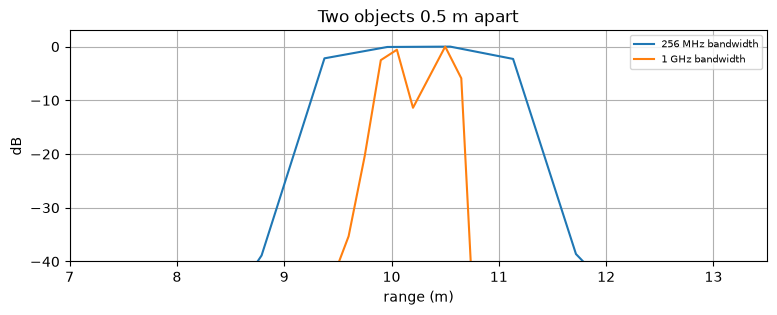

In [6]:
pair = [(10.0, 1.0), (10.5, 1.0)]
for slope, label in [(SLOPE, "256 MHz bandwidth"), (1e9 / (NS / FS_ADC), "1 GHz bandwidth")]:
    r, p = range_profile(if_signal(pair, slope=slope, noise=0.01), slope=slope)
    plt.plot(r, p - p.max(), label=label)
plt.xlim(7, 13.5); plt.ylim(-40, 3); plt.xlabel("range (m)"); plt.ylabel("dB")
plt.legend(fontsize=7); plt.title("Two objects 0.5 m apart"); plt.show()

## 5. Velocity from Doppler: the range-Doppler map

**What it is.** If an object moves, its distance changes slightly between one chirp and the next. The range barely changes (millimetres), but the **phase** of its echo changes a lot, because millimetres are a big fraction of a 3.9 mm wavelength. The phase change per chirp is

`delta_phi = 4 * pi * v * T_c / lambda`

where `v` is the radial velocity and `T_c` the time between chirps. A steady phase change from chirp to chirp is just a frequency (the **Doppler frequency** `f_D = 2v / lambda`), so a **second FFT across chirps** measures velocity.

**Simple analogy.** Take photos of a ticking clock hand at regular intervals. Even if the hand moves only a little, comparing many photos shows exactly how fast it turns.

**How it works.** The radar sends a **frame** of `N_c` chirps. We stack the IF samples in a matrix (chirps x samples), then:
1. **Range FFT** along each row (fast time, inside one chirp).
2. **Doppler FFT** along each column (slow time, across chirps).
3. The result is the **range-Doppler map (RD map)**: one bright spot per object at (range, velocity).

Key formulas:
- **max unambiguous velocity**: `v_max = lambda / (4 * T_c)`
- **velocity resolution**: `dv = lambda / (2 * N_c * T_c)`

In [7]:
NC, TC, NRX = 128, 40e-6, 8                       # chirps per frame, chirp period, virtual antennas
print(f"v_max = ±{LAM / (4 * TC):.1f} m/s, velocity resolution = {LAM / (2 * NC * TC):.2f} m/s")

def simulate_frame(targets, noise=1.0):
    """Radar data cube (antennas x chirps x samples) for point targets.
    targets: list of dicts with range r (m), velocity v (m/s, + = moving away), angle (deg), rcs (m^2).
    Simplified: no range migration, ideal antennas, amplitude ~ sqrt(rcs) / r^2 (radar equation)."""
    n, m, k = np.arange(NS), np.arange(NC), np.arange(NRX)
    cube = noise * (rng.normal(size=(NRX, NC, NS)) + 1j * rng.normal(size=(NRX, NC, NS))) / np.sqrt(2)
    for tg in targets:
        amp = 60 * np.sqrt(tg["rcs"]) / tg["r"] ** 2
        fast = np.exp(2j * np.pi * (2 * SLOPE * tg["r"] / C) * n / FS_ADC)              # range -> beat freq
        slow = np.exp(2j * np.pi * (2 * tg["v"] / LAM) * m * TC)                         # velocity -> Doppler
        space = np.exp(1j * np.pi * k * np.sin(np.radians(tg["angle"])))                 # angle -> phase step
        phase0 = np.exp(2j * np.pi * rng.random())
        cube += amp * phase0 * space[:, None, None] * slow[None, :, None] * fast[None, None, :]
    return cube

def range_doppler(cube):
    win = np.hanning(NS)[None, None, :] * np.hanning(NC)[None, :, None]
    rd = np.fft.fft(np.fft.fft(cube * win, axis=2), axis=1)      # range FFT, then Doppler FFT
    return np.fft.fftshift(rd, axes=1)                            # put zero velocity in the middle

RANGE_AX = np.arange(NS) * FS_ADC / NS * C / (2 * SLOPE)
VEL_AX = np.fft.fftshift(np.fft.fftfreq(NC, TC)) * LAM / 2

v_max = ±24.4 m/s, velocity resolution = 0.38 m/s


Now a small street scene: a car approaching at 8 m/s (a few reflecting points spread over its length), two pedestrians walking in opposite directions, a lamp post, and a guard rail along the road (many weak static points).

data cube (8, 128, 256) (antennas, chirps, samples) simulated and processed in 0.05 s


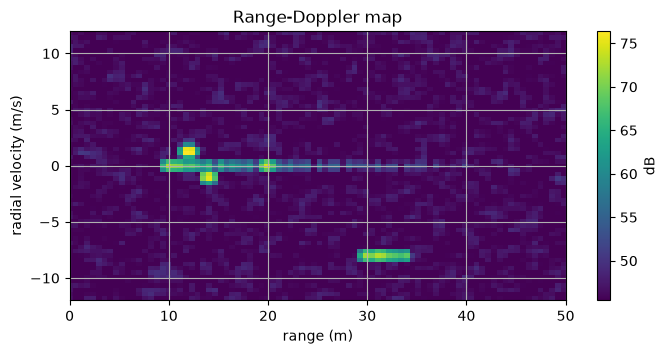

In [8]:
def street_scene(shift_s=0.0):
    """Targets of a simple street scene, moved forward by shift_s seconds (for tracking later)."""
    tg = []
    for dr, da in [(0, 0), (0.8, 1.2), (1.6, -1.0), (2.6, 0.8), (3.6, -0.5)]:          # the car body
        tg.append(dict(r=30 + dr - 8 * shift_s, v=-8.0, angle=10 + da, rcs=8))
    tg.append(dict(r=12 + 1.3 * shift_s, v=1.3, angle=-20, rcs=0.8))                    # pedestrian 1 (away)
    tg.append(dict(r=14 - 1.0 * shift_s, v=-1.0, angle=-12, rcs=0.8))                   # pedestrian 2 (towards)
    tg.append(dict(r=20, v=0.0, angle=25, rcs=2))                                       # lamp post
    for y in np.arange(8, 40, 1.5):                                                     # guard rail at x = +6 m
        tg.append(dict(r=np.hypot(6, y), v=0.0, angle=np.degrees(np.arctan2(6, y)), rcs=0.1))
    return tg

t0 = time.time()
cube = simulate_frame(street_scene())
RD = range_doppler(cube)
rd_power = (np.abs(RD) ** 2).sum(axis=0)                           # add up power over antennas
print(f"data cube {cube.shape} (antennas, chirps, samples) simulated and processed in {time.time() - t0:.2f} s")
plt.figure(figsize=(8, 3.5))
plt.pcolormesh(RANGE_AX, VEL_AX, 10 * np.log10(rd_power), shading="auto", vmin=np.percentile(10 * np.log10(rd_power), 50))
plt.colorbar(label="dB"); plt.xlim(0, 50); plt.ylim(-12, 12)
plt.xlabel("range (m)"); plt.ylabel("radial velocity (m/s)"); plt.title("Range-Doppler map"); plt.show()

**What just happened?** Each object shows up as a bright spot at its range and speed. The car (around 30-34 m, -8 m/s, negative = approaching in our convention) appears as a short streak because it has several reflecting points. The pedestrians sit at about +1.3 and -1.0 m/s. The lamp post and guard rail all lie on the **zero-velocity line**: static objects. Radar measures velocity **directly**, in a single frame; cameras and LiDAR must compare frames to get it.

## 6. Angle of arrival and the MIMO virtual array

**What it is.** With several receive antennas in a row, an echo from the side reaches each antenna at a slightly different time, so each antenna sees a slightly different **phase**. With spacing `d = lambda / 2`, neighbouring antennas differ by `pi * sin(theta)`, where `theta` is the angle of arrival. A **third FFT, across antennas**, turns that phase step into an angle.

**Simple analogy.** You can tell where a sound comes from because it reaches one ear slightly before the other. More "ears" in a row give a sharper sense of direction.

**MIMO virtual array.** **MIMO** (multiple-input multiple-output) radars use several transmit (TX) and several receive (RX) antennas. With clever placement, each TX-RX pair acts like a separate receive antenna at a new position, so **2 TX x 4 RX = 8 "virtual" antennas**. Angular resolution is roughly `2 / N_virtual` radians at the centre (about 14 degrees for 8, about 1-2 degrees for the large arrays of modern "imaging" radars). The transmitters must take turns or be coded so the receiver can tell them apart; here we simply simulate the 8 virtual antennas directly.

```
TX1  TX2              RX1 RX2 RX3 RX4                  virtual array (8 elements)
 o----o (4d apart)     x   x   x   x  (d apart)   ->   x x x x x x x x
```

In [9]:
NANG = 64                                                   # zero-padded angle FFT size
ANGLE_AX = np.degrees(np.arcsin(np.clip(2 * np.fft.fftshift(np.fft.fftfreq(NANG)), -1, 1)))

def angle_spectrum(snapshot):
    """snapshot: complex values at one (range, Doppler) cell for each antenna -> power per angle."""
    a = np.fft.fftshift(np.fft.fft(snapshot * np.hanning(NRX) , n=NANG))
    return np.abs(a) ** 2

# Angle of the strongest cell of each pedestrian:
for name, v_true in [("pedestrian 1", 1.3), ("pedestrian 2", -1.0)]:
    d_bin = np.argmin(np.abs(VEL_AX - v_true))
    r_bin = np.argmax(rd_power[d_bin, :60])
    ang = ANGLE_AX[np.argmax(angle_spectrum(RD[:, d_bin, r_bin]))]
    print(f"{name}: range {RANGE_AX[r_bin]:.1f} m, velocity {VEL_AX[d_bin]:+.2f} m/s, angle {ang:+.1f} deg")
print("(true: pedestrian 1 at 12 m, +1.3 m/s, -20 deg; pedestrian 2 at 14 m, -1.0 m/s, -12 deg)")

pedestrian 1: range 11.7 m, velocity +1.14 m/s, angle -20.1 deg
pedestrian 2: range 14.1 m, velocity -1.14 m/s, angle -12.6 deg
(true: pedestrian 1 at 12 m, +1.3 m/s, -20 deg; pedestrian 2 at 14 m, -1.0 m/s, -12 deg)


## 7. CFAR detection: deciding what is a real object

**What it is.** After the FFTs we have a map of power values. We must decide which cells are **objects** and which are **noise**. A fixed threshold fails, because the noise level changes across the map (more clutter near the radar, more noise at some frequencies). **CFAR (Constant False Alarm Rate)** sets a **local** threshold for every cell, based on the noise around it.

**Simple analogy.** In a quiet library a normal voice stands out; at a concert you need to shout. CFAR judges each cell against its own neighbourhood's "background volume".

**How CA-CFAR (cell-averaging CFAR) works.**
1. For each **cell under test (CUT)**, look at **training cells** on both sides.
2. Skip a few **guard cells** right next to the CUT, so the object's own energy does not raise its threshold.
3. Noise estimate = mean of training cells. Threshold = `alpha * noise estimate`.
4. For `N` training cells and a desired **probability of false alarm** `Pfa`, the classic formula (for noise power that follows an exponential distribution) is `alpha = N * (Pfa^(-1/N) - 1)`.

```
 [ train | train | guard | CUT | guard | train | train ]
   <---- averaged ---->           <---- averaged ---->
```

First in 1-D, on a range profile with strong clutter near the radar:

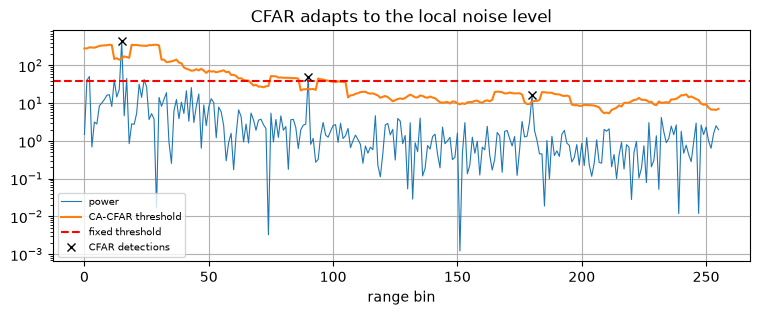

CFAR detections at bins: [ 15  90 180]  (objects at 15, 90, 180)
fixed threshold detections at bins: [ 1  2 12 15 17 24 90]


In [10]:
def ca_cfar_1d(power, n_train=12, n_guard=3, pfa=1e-4):
    N = 2 * n_train
    alpha = N * (pfa ** (-1 / N) - 1)
    kernel = np.r_[np.ones(n_train), np.zeros(2 * n_guard + 1), np.ones(n_train)] / N
    noise = np.convolve(power, kernel, mode="same")          # mean of the training cells
    return power > alpha * noise, alpha * noise

nbin = 256
rbins = np.arange(nbin)
noise_floor = 1 + 30 * np.exp(-rbins / 25)                  # strong clutter close to the radar
power = noise_floor * rng.exponential(size=nbin)            # noise power is exponential (square-law)
for b, snr in [(15, 25), (90, 25), (180, 15)]:              # three objects
    power[b] += snr * noise_floor[b]
det, thr = ca_cfar_1d(power)
fixed = 40.0
plt.semilogy(rbins, power, lw=0.8, label="power")
plt.semilogy(rbins, thr, label="CA-CFAR threshold")
plt.axhline(fixed, color="r", ls="--", label="fixed threshold")
plt.plot(rbins[det], power[det], "kx", label="CFAR detections")
plt.xlabel("range bin"); plt.legend(fontsize=7); plt.title("CFAR adapts to the local noise level"); plt.show()
print("CFAR detections at bins:", rbins[det], " (objects at 15, 90, 180)")
print("fixed threshold detections at bins:", rbins[power > fixed])

The fixed threshold fires on clutter near the radar and misses the weak far object. CFAR follows the noise floor and finds all three. Now the 2-D version on the range-Doppler map (a ring of training cells around a block of guard cells):

In [11]:
def ca_cfar_2d(P, train=(6, 3), guard=(2, 1), pfa=1e-5):
    """P: power map (Doppler x range). train/guard sizes are (range, Doppler) half-widths."""
    (tr, td), (gr, gd) = train, guard
    kernel = np.ones((2 * (td + gd) + 1, 2 * (tr + gr) + 1))
    kernel[td:td + 2 * gd + 1, tr:tr + 2 * gr + 1] = 0           # remove guard cells and the CUT
    N = kernel.sum()
    alpha = N * (pfa ** (-1 / N) - 1)
    noise = ndimage.convolve(P, kernel / N, mode="wrap")         # Doppler wraps around; fine for a demo
    return P > alpha * noise

det2d = ca_cfar_2d(rd_power)
d_idx, r_idx = np.nonzero(det2d)
print(f"{det2d.sum()} detections out of {det2d.size} cells")
for d, r in zip(d_idx, r_idx):
    print(f"  range {RANGE_AX[r]:5.1f} m, velocity {VEL_AX[d]:+5.2f} m/s")

18 detections out of 32768 cells
  range  31.1 m, velocity -8.37 m/s
  range  29.9 m, velocity -7.99 m/s
  range  30.5 m, velocity -7.99 m/s
  range  31.1 m, velocity -7.99 m/s
  range  31.6 m, velocity -7.99 m/s
  range  32.2 m, velocity -7.99 m/s
  range  13.5 m, velocity -1.14 m/s
  range  14.1 m, velocity -1.14 m/s
  range  14.1 m, velocity -0.76 m/s
  range  19.9 m, velocity -0.38 m/s
  range  19.3 m, velocity +0.00 m/s
  range  19.9 m, velocity +0.00 m/s
  range  20.5 m, velocity +0.00 m/s
  range  19.9 m, velocity +0.38 m/s
  range  11.7 m, velocity +1.14 m/s
  range  12.3 m, velocity +1.14 m/s
  range  11.7 m, velocity +1.52 m/s
  range  12.3 m, velocity +1.52 m/s


**Masking.** Look at what is *missing*: the guard rail, a long line of weak static reflectors, is not detected at all. Its points sit in each other's training cells and raise each other's threshold. The same can happen to a weak pedestrian next to a strong car. This **masking** is a known weakness of CA-CFAR; variants such as **OS-CFAR** (ordered-statistic: use a middle value of the sorted training cells instead of the mean) are more robust, and many systems find static road edges with separate methods. Choosing the training/guard sizes and `Pfa` is a real engineering trade-off between missed objects and false alarms.

## 8. From detections to objects: angle + clustering (DBSCAN)

Each detection is one cell. A car produces many detections. We:
1. estimate the **angle** of each detection with the angle FFT (section 6),
2. convert (range, angle) to **x, y** coordinates (a bird's-eye view; this list of points is a **radar point cloud**, like a sparse version of the LiDAR point clouds in [notebook 04](04_lidar_point_clouds_from_zero.ipynb)),
3. group nearby points with similar velocity using **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise): points with enough neighbours within distance `eps` form a cluster; isolated points are labelled noise (-1). It does not need the number of clusters in advance, which suits radar.

18 points -> 4 clusters (+ 1 noise points)
cluster 0:   6 points, centre x=   5.5 m, y= 30.6 m, velocity -8.05 m/s  [MOVING]
cluster 1:   3 points, centre x=  -3.0 m, y= 13.5 m, velocity -1.01 m/s  [MOVING]
cluster 2:   4 points, centre x=   7.9 m, y= 18.1 m, velocity +0.00 m/s  [static]
cluster 3:   4 points, centre x=  -4.1 m, y= 11.3 m, velocity +1.33 m/s  [MOVING]


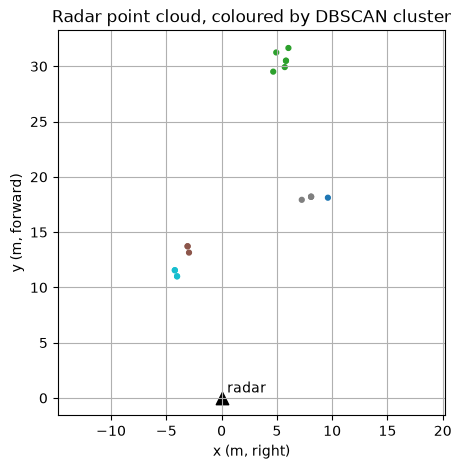

In [12]:
def detections_to_points(RD, det2d):
    d_idx, r_idx = np.nonzero(det2d)
    power_db = 10 * np.log10(rd_power_of(RD))
    pts = []
    for d, r in zip(d_idx, r_idx):
        ang = ANGLE_AX[np.argmax(angle_spectrum(RD[:, d, r]))]
        rr, th = RANGE_AX[r], np.radians(ang)
        pts.append([rr * np.sin(th), rr * np.cos(th), VEL_AX[d], power_db[d, r]])
    return np.array(pts)                                            # columns: x, y, velocity, power(dB)

def rd_power_of(RD):
    return (np.abs(RD) ** 2).sum(axis=0)

def cluster(points, eps=1.5, min_samples=2, vel_weight=0.7):
    feats = np.column_stack([points[:, 0], points[:, 1], vel_weight * points[:, 2]])
    return DBSCAN(eps=eps, min_samples=min_samples).fit_predict(feats)

pts = detections_to_points(RD, det2d)
labels = cluster(pts)
print(f"{len(pts)} points -> {labels.max() + 1} clusters (+ {np.sum(labels == -1)} noise points)")
for c in range(labels.max() + 1):
    p = pts[labels == c]
    kind = "static" if abs(p[:, 2].mean()) < 0.3 else "MOVING"
    print(f"cluster {c}: {len(p):>3} points, centre x={p[:, 0].mean():6.1f} m, y={p[:, 1].mean():5.1f} m,"
          f" velocity {p[:, 2].mean():+5.2f} m/s  [{kind}]")

plt.figure(figsize=(5, 5))
plt.scatter(pts[:, 0], pts[:, 1], c=labels, cmap="tab10", s=12)
plt.scatter([0], [0], marker="^", c="k", s=80); plt.text(0.5, 0.5, "radar")
plt.xlabel("x (m, right)"); plt.ylabel("y (m, forward)"); plt.axis("equal")
plt.title("Radar point cloud, coloured by DBSCAN cluster"); plt.show()

**What just happened?** The car, the two pedestrians and the lamp post come out as separate clusters, each with a **velocity** attached; isolated stray points are labelled noise. A driver-assistance system would now keep the moving clusters as "objects", treat static clusters as the environment, and pass the objects to a **tracker**. Because the angular resolution of 8 antennas is coarse (about 14 degrees), objects at similar range and speed can still merge; this is a main reason for the much larger antenna arrays of **4D imaging radars** (which also measure elevation).

## 9. Tracking teaser

A **tracker** follows each object over time: it predicts where the object should be in the next frame, **associates** the new detections with existing tracks, and smooths the noisy measurements. Radar gives velocity directly, which makes prediction easier. Here is the simplest possible version: predict with constant velocity and match each new cluster to the nearest prediction. [Notebook 05](05_sensor_fusion_kalman_filters_and_tracking.ipynb) does this properly with **Kalman filters**.

```mermaid
flowchart LR
    F[Radar frame] --> RD[Range-Doppler-angle FFTs]
    RD --> CF[CFAR detections]
    CF --> PC[Point cloud x, y, v]
    PC --> CL[Clustering DBSCAN]
    CL --> AS[Associate with tracks]
    AS --> KF[Kalman filter update]
    KF --> PR[Predict next frame]
    PR --> AS
    KF --> OUT[Tracked objects<br/>position + velocity]
```

In [13]:
def moving_objects(points, labels):
    objs = []
    for c in range(labels.max() + 1):
        p = points[labels == c]
        if abs(p[:, 2].mean()) > 0.3:                                  # keep moving clusters only
            objs.append(np.r_[p[:, :2].mean(0), p[:, 2].mean()])
    return np.array(objs)

DT = 0.5                                                                # next frame 0.5 s later
objs_a = moving_objects(pts, labels)
cube_b = simulate_frame(street_scene(shift_s=DT)); RD_b = range_doppler(cube_b)
pts_b = detections_to_points(RD_b, ca_cfar_2d(rd_power_of(RD_b)))
objs_b = moving_objects(pts_b, cluster(pts_b))
for o in objs_a:
    direction = o[:2] / np.linalg.norm(o[:2])                           # radial direction
    pred = o[:2] + direction * o[2] * DT                                # constant radial velocity
    j = np.argmin(np.linalg.norm(objs_b[:, :2] - pred, axis=1))
    print(f"object at ({o[0]:5.1f}, {o[1]:5.1f}) v={o[2]:+.1f} -> predicted ({pred[0]:5.1f}, {pred[1]:5.1f})"
          f" -> matched ({objs_b[j, 0]:5.1f}, {objs_b[j, 1]:5.1f}), error {np.linalg.norm(objs_b[j, :2] - pred):.2f} m")

object at (  5.5,  30.6) v=-8.1 -> predicted (  4.8,  26.6) -> matched (  5.0,  26.8), error 0.28 m
object at ( -3.0,  13.5) v=-1.0 -> predicted ( -2.9,  13.0) -> matched ( -3.0,  13.3), error 0.31 m
object at ( -4.1,  11.3) v=+1.3 -> predicted ( -4.4,  11.9) -> matched ( -4.3,  11.8), error 0.08 m


## 10. Micro-Doppler: the body's motion fingerprint

**What it is.** A walking person is not one point moving at one speed. The torso moves forward steadily, while arms and legs swing back and forth, faster and slower than the torso. Each part adds its own small Doppler shift around the main one. These extra shifts are called **micro-Doppler**. In a **spectrogram** of the radar signal over time (STFT, notebook 01), they draw a characteristic pattern: a strong torso line with wavy limb "bands" around it.

**Simple analogy.** The sound of footsteps tells you whether someone is walking, running or limping, without seeing them. Micro-Doppler is the radar version: the *rhythm and spread* of speeds says what the body is doing.

**How we simulate it.** We follow one person in one range bin with a 60 GHz radar (wavelength 5 mm) that samples the slow-time signal at 4 kHz (one chirp every 0.25 ms). The body is modelled as six reflecting points (torso, head, two arms, two legs). Each point has a radial velocity curve `v(t)`; its distance is `r(t) = r0 + integral of v`, and the radar sample is the sum of `a * exp(j * 4 * pi * r(t) / lambda)`. The activities:

| Activity | Torso / head | Limbs |
|---|---|---|
| walk | steady speed 0.6-1.6 m/s towards or away | legs and arms swing around the torso speed |
| still | almost nothing (breathing, small sway) | occasional small hand movement |
| sit down | smooth bump to about 0.5-1 m/s, about 1-1.5 s | small |
| bend and pick up | down, then back up (positive then negative speed) | small |
| **fall** | speed grows fast (gravity) to about 2-3 m/s in under a second, then **stops abruptly**; stillness afterwards | arms flail |

Each simulated person has their own size, walking speed and gait; the radar sees them from a random angle (only the part of the motion along the line of sight counts).

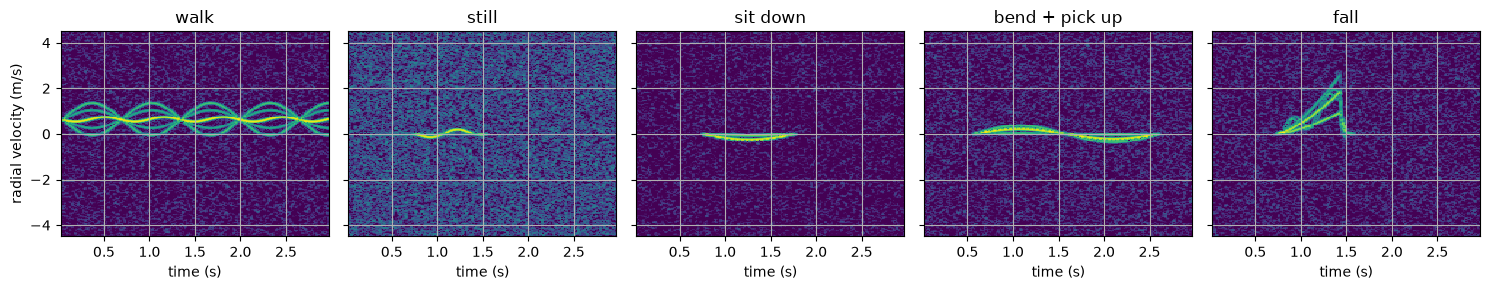

In [14]:
LAM60, PRF, CLIP = C / 60e9, 4000, 3.0
t_md = np.arange(int(PRF * CLIP)) / PRF
MD_CLASSES = ["walk", "still", "sit down", "bend + pick up", "fall"]
PARTS = {"torso": 1.0, "head": 0.35, "arm_l": 0.25, "arm_r": 0.25, "leg_l": 0.4, "leg_r": 0.4}   # reflectivity

def bump(t, t0, dur):
    """0 outside [t0, t0+dur], a smooth half-sine inside."""
    x = (t - t0) / dur
    return np.where((x >= 0) & (x <= 1), np.sin(np.pi * np.clip(x, 0, 1)), 0.0)

def body_velocities(kind, person):
    t = t_md; U = rng.uniform
    aspect = U(0.4, 1.0) * rng.choice([-1, 1])          # how much of the motion is along the radar's line of sight
    breath = 0.005 * np.sin(2 * np.pi * U(0.2, 0.4) * t)
    v = {p: breath + 0.01 * signal.sosfilt(SWAY, rng.normal(size=t.size)) for p in PARTS}
    if kind == "walk":
        v0, fg = person["speed"] * U(0.85, 1.15), person["gait"] * U(0.9, 1.1)   # speed, gait cycles per second
        ph = U(0, 2 * np.pi)
        v["torso"] = v0 * (1 + 0.15 * np.sin(4 * np.pi * fg * t + ph)); v["head"] = v["torso"].copy()
        v["leg_l"] = v0 * (1 + 1.1 * np.sin(2 * np.pi * fg * t + ph)); v["leg_r"] = v0 * (1 - 1.1 * np.sin(2 * np.pi * fg * t + ph))
        v["arm_l"] = v0 * (1 - 0.6 * np.sin(2 * np.pi * fg * t + ph)); v["arm_r"] = v0 * (1 + 0.6 * np.sin(2 * np.pi * fg * t + ph))
    elif kind == "still":
        if rng.random() < 0.5:                           # a small hand gesture
            v["arm_r"] = v["arm_r"] + U(0.2, 0.5) * np.sin(2 * np.pi * U(1, 2) * t) * bump(t, U(0.3, 1.5), U(0.6, 1.2))
    elif kind == "sit down":
        t0, dur, peak = U(0.4, 1.2), U(0.9, 1.6), U(0.5, 1.0) * person["size"]
        for p, k in [("torso", 1.0), ("head", 1.2), ("arm_l", 0.6), ("arm_r", 0.6), ("leg_l", 0.3), ("leg_r", 0.3)]:
            v[p] = v[p] + k * peak * bump(t, t0, dur)
    elif kind == "bend + pick up":
        t0, dur, peak = U(0.3, 0.8), U(1.6, 2.2), U(0.5, 0.9) * person["size"]
        updown = np.where((t >= t0) & (t <= t0 + dur), np.sin(2 * np.pi * (t - t0) / dur), 0.0)
        for p, k in [("torso", 0.8), ("head", 1.4), ("arm_l", 1.0), ("arm_r", 1.0), ("leg_l", 0.1), ("leg_r", 0.1)]:
            v[p] = v[p] + k * peak * updown
    elif kind == "fall":
        t0, dur, peak = U(0.4, 1.0), U(0.5, 0.9), U(1.8, 3.0) * person["size"]
        x = np.clip((t - t0) / dur, 0, None)
        prof = np.where(x <= 1, x ** 1.5, np.exp(-(x - 1) * dur * 40) * (1 - 0.3 * np.sin(np.minimum(x - 1, 1) * 60)))
        prof = np.where(t < t0, 0, prof)                 # accelerate, then stop abruptly with a small rebound
        for p, k in [("torso", 1.0), ("head", 1.4), ("leg_l", 0.5), ("leg_r", 0.5)]:
            v[p] = v[p] + k * peak * prof
        for p in ["arm_l", "arm_r"]:                     # arms flail
            v[p] = v[p] + peak * prof * U(0.8, 1.3) + U(0.3, 0.8) * np.sin(2 * np.pi * U(2, 4) * t) * (prof > 0.05)
    return {p: aspect * v[p] for p in PARTS}

SWAY = signal.butter(2, 1.0, fs=PRF, output="sos")

def radar_slow_time(kind, person, snr_db=15):
    vel = body_velocities(kind, person)
    x = np.zeros(t_md.size, complex)
    for p, a in PARTS.items():
        r = np.cumsum(vel[p]) / PRF                          # change of distance over time (m)
        x += a * person["size"] * np.exp(1j * 4 * np.pi * r / LAM60 + 1j * rng.uniform(0, 2 * np.pi))
    x += 3.0 * np.exp(1j * rng.uniform(0, 2 * np.pi))       # strong static clutter (walls, furniture)
    x -= x.mean()                                            # remove the static part (zero-Doppler removal)
    noise = np.sqrt(np.mean(np.abs(x) ** 2) / 10 ** (snr_db / 10) / 2)
    return x + noise * (rng.normal(size=x.size) + 1j * rng.normal(size=x.size))

def md_spectrogram(x):
    f, tt, S = signal.spectrogram(x, fs=PRF, window="hann", nperseg=256, noverlap=192,
                                  return_onesided=False, mode="psd")
    f, S = np.fft.fftshift(f), np.fft.fftshift(S, axes=0)
    return f * LAM60 / 2, tt, S                              # Doppler frequency -> velocity

people = [{"speed": rng.uniform(0.6, 1.5), "gait": rng.uniform(0.8, 1.0), "size": rng.uniform(0.8, 1.2)}
          for _ in range(8)]
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharey=True)
for ax, kind in zip(axes, MD_CLASSES):
    vax, tt, S = md_spectrogram(radar_slow_time(kind, people[0]))
    SdB = 10 * np.log10(S / S.max() + 1e-12)
    ax.pcolormesh(tt, vax, SdB, shading="auto", vmin=-40, vmax=0)
    ax.set_title(kind); ax.set_xlabel("time (s)"); ax.set_ylim(-4.5, 4.5)
axes[0].set_ylabel("radial velocity (m/s)")
plt.tight_layout(); plt.show()

**What just happened?** Each activity draws a different picture. Walking shows a steady torso line plus wavy limb bands with a regular rhythm. Sitting down and bending are slow, smooth bumps (bending goes up *and* down). A **fall** is a fast, strong, short streak that ends abruptly, followed by stillness. This is how radar can detect falls in a bathroom **without a camera and without a wearable**.

### Classifying activities and falls from micro-Doppler features

We make features from each spectrogram (in the spirit of notebook 01): per time frame we compute the **power-weighted mean velocity** (the "centroid") and the **envelope** (the highest speed with noticeable power); then we summarize them over the clip. We evaluate with **GroupKFold by person** so that the model is always tested on people it has never seen.

480 clips simulated and featurized in 4.0 s; feature table (480, 13)


5-class accuracy on unseen people: 0.960


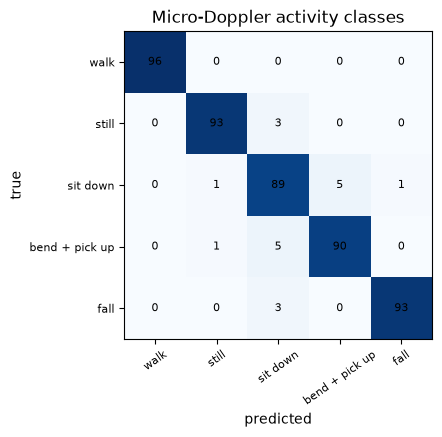

fall sensitivity = 0.97, false fall alarms = 1 of 384 non-fall clips


In [15]:
def md_features(x):
    vax, tt, S = md_spectrogram(x)
    P = S / S.max()
    w = P / (P.sum(0, keepdims=True) + 1e-12)
    centroid = (w * vax[:, None]).sum(0)                                     # mean velocity per frame
    spread = np.sqrt((w * (vax[:, None] - centroid) ** 2).sum(0))
    strong = P > 10 ** (-25 / 10)                                            # within 25 dB of the peak
    env = np.array([np.abs(vax[s]).max() if s.any() else 0 for s in strong.T])  # max speed per frame
    energy = P.sum(0); energy = energy / energy.max()
    i_peak = env.argmax()
    c = centroid - centroid.mean()
    cs = np.abs(np.fft.rfft(c * np.hanning(c.size))); cf = np.fft.rfftfreq(c.size, tt[1] - tt[0])
    rhythm = cs[(cf > 0.6) & (cf < 3)].max() / (cs.sum() + 1e-9)            # periodicity (walking)
    after = env[i_peak + 6:] if i_peak + 6 < len(env) - 3 else env[-3:]
    return [env.max(), env.mean(), env.std(), np.abs(centroid).max(), centroid.max() - centroid.min(),
            spread.mean(), spread.max(), (env > 1.0).mean(), np.abs(np.diff(env)).max(),
            after.mean(), energy.std(), rhythm, np.abs(centroid).mean()]

X_md, y_md, g_md = [], [], []
t0 = time.time()
for pid, person in enumerate(people):
    for label, kind in enumerate(MD_CLASSES):
        for _ in range(12):                                                  # 12 clips per class per person
            X_md.append(md_features(radar_slow_time(kind, person, snr_db=rng.uniform(8, 20))))
            y_md.append(label); g_md.append(pid)
X_md, y_md, g_md = np.array(X_md), np.array(y_md), np.array(g_md)
print(f"{len(y_md)} clips simulated and featurized in {time.time() - t0:.1f} s; feature table {X_md.shape}")

clf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
pred = cross_val_predict(clf, X_md, y_md, groups=g_md, cv=GroupKFold(n_splits=4))
print(f"5-class accuracy on unseen people: {accuracy_score(y_md, pred):.3f}")
cm = confusion_matrix(y_md, pred)
plt.figure(figsize=(4.8, 4)); plt.imshow(cm, cmap="Blues"); plt.grid(False)
plt.xticks(range(5), MD_CLASSES, rotation=35, fontsize=8); plt.yticks(range(5), MD_CLASSES, fontsize=8)
for i in range(5):
    for j in range(5):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Micro-Doppler activity classes"); plt.show()

fall = MD_CLASSES.index("fall")
tp = ((pred == fall) & (y_md == fall)).sum(); fn = ((pred != fall) & (y_md == fall)).sum()
fp = ((pred == fall) & (y_md != fall)).sum()
print(f"fall sensitivity = {tp / (tp + fn):.2f}, false fall alarms = {fp} of {(y_md != fall).sum()} non-fall clips")

**What just happened?** Simple hand-made features from the spectrogram separate the five activities well on unseen people in this simulation. The usual hard pair is **sit down vs bend + pick up** (both slow torso motions) and sometimes a **fast sit-down vs a fall**. As in [notebook 02](02_imu_activity_recognition_and_fall_detection.ipynb), in a real product you would report fall sensitivity and **false alarms per day** on long real-life recordings, not clip accuracy.

**What real systems do.** Instead of hand-made features, most recent research feeds the spectrogram (or a sequence of range-Doppler maps) as an image to a **CNN** or a small transformer, often with **data augmentation** and **simulated data** to make up for the lack of real falls (see [notebook 06](06_sensor_data_for_generative_and_foundation_models.ipynb) for synthetic data and sim-to-real). The physics above is exactly what such simulators use, in a more detailed form (for example, full-body motion-capture models).

## 11. Vital signs: breathing from radar phase

**What it is.** When a person breathes, the chest moves a few millimetres. For a 60 GHz radar (wavelength 5 mm), a chest movement `d` changes the echo phase by `4 * pi * d / lambda`, so **1 mm of movement is about 2.5 radians of phase**. By tracking the phase of the range bin that contains the person, radar can measure breathing rate, and in good conditions even heart rate, **without touching the person**.

**Simple analogy.** A long lever: a tiny movement at one end gives a big, easy-to-see swing at the other. The short wavelength is the lever.

**How it works.**
1. Find the range bin of the person (range FFT, as in section 4) and take its complex value in every frame (here 20 frames per second).
2. Remove the **static clutter** (the constant echo from walls and furniture) by subtracting the mean, otherwise the phase is biased.
3. Take the **phase** with `np.angle`. It jumps between `-pi` and `pi`, so **unwrap** it (`np.unwrap` adds or subtracts `2 * pi` at each jump).
4. Convert phase to displacement, band-pass filter (breathing about 0.1-0.6 Hz, heart about 0.8-2.5 Hz), and find the strongest frequency.

breathing: estimated 15.0 /min (true 15)
heart    : estimated 69.0 /min (true 69)
(this clean simulation makes heart rate look easy; in real rooms breathing harmonics and body motion often swamp it)


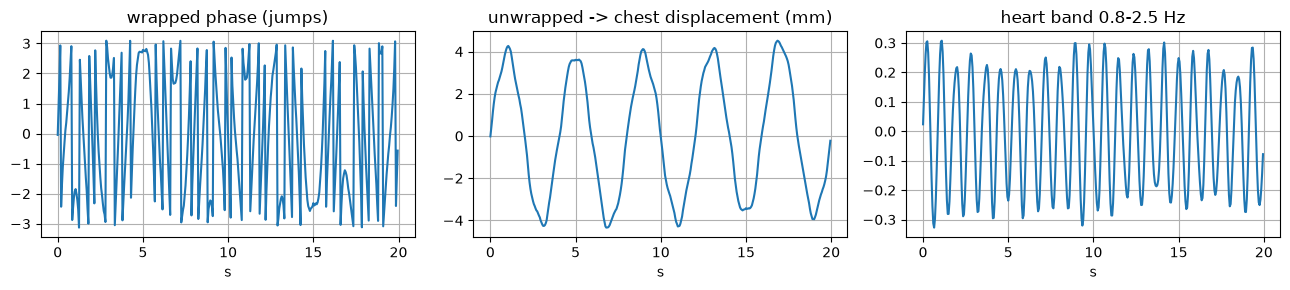

In [16]:
FPS, DUR_V = 20, 60.0                                     # 20 frames per second, 60 s
tv = np.arange(0, DUR_V, 1 / FPS)
br_hz, hr_hz = 0.25, 1.15                                 # true: 15 breaths/min, 69 beats/min
chest = 4e-3 * np.sin(2 * np.pi * br_hz * tv) + 0.25e-3 * np.sin(2 * np.pi * hr_hz * tv)   # metres
chest += 0.3e-3 * signal.sosfilt(signal.butter(2, 0.05, fs=FPS, output="sos"), rng.normal(size=tv.size)) * 20
person_echo = np.exp(1j * 4 * np.pi * (1.2 + chest) / LAM60)          # person at 1.2 m
clutter = 0.8 * np.exp(1j * 1.0)                                      # static reflection, same range bin
iq = person_echo + clutter + 0.03 * (rng.normal(size=tv.size) + 1j * rng.normal(size=tv.size))

iq_clean = iq - iq.mean()                                             # remove static clutter
phase_wrapped = np.angle(iq_clean)
phase = np.unwrap(phase_wrapped)
disp_mm = phase * LAM60 / (4 * np.pi) * 1000                          # phase -> displacement (mm)

def rate_per_min(x, lo, hi):
    y = signal.sosfiltfilt(signal.butter(3, [lo, hi], btype="band", fs=FPS, output="sos"), x)
    n = 8 * len(y)                                                    # zero padding for a smoother peak
    spec = np.abs(np.fft.rfft(y * np.hanning(len(y)), n=n)); f = np.fft.rfftfreq(n, 1 / FPS)
    band = (f >= lo) & (f <= hi)
    return f[band][np.argmax(spec[band])] * 60, y

br_est, br_sig = rate_per_min(disp_mm, 0.1, 0.6)
hr_est, hr_sig = rate_per_min(disp_mm, 0.8, 2.5)
print(f"breathing: estimated {br_est:.1f} /min (true {br_hz * 60:.0f})")
print(f"heart    : estimated {hr_est:.1f} /min (true {hr_hz * 60:.0f})")
print("(this clean simulation makes heart rate look easy; in real rooms breathing harmonics and body motion often swamp it)")

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
axes[0].plot(tv[:400], phase_wrapped[:400]); axes[0].set_title("wrapped phase (jumps)"); axes[0].set_xlabel("s")
axes[1].plot(tv[:400], disp_mm[:400]); axes[1].set_title("unwrapped -> chest displacement (mm)"); axes[1].set_xlabel("s")
axes[2].plot(tv[:400], hr_sig[:400]); axes[2].set_title("heart band 0.8-2.5 Hz"); axes[2].set_xlabel("s")
plt.tight_layout(); plt.show()

**Where this is used.**
- **In-cabin child presence detection**: a 60 GHz radar in the car roof detects the breathing of a child left in a rear seat (even under a blanket) and warns the driver. Vehicle safety rating programmes such as Euro NCAP reward this feature.
- **Sleep and elder-care monitoring**: breathing rate and presence in bed without wearables or cameras.
- **Driver monitoring**: drowsiness and health signals. Heart rate from radar is much harder than breathing and is still an active research and product area.

### Gesture sensing (brief)

Short-range 60 GHz radars can recognise **hand gestures** (swipe, tap, finger rub) from sequences of range-Doppler maps or micro-Doppler spectrograms; Google's Project Soli (Lien et al., 2016) is the best-known example. The ML pipeline is the same as in section 10: small radar "images" over time -> features or a small CNN/RNN -> gesture class. Advantages: works in the dark, through thin plastic, and does not record images of the user.

## 12. Radar vs camera vs LiDAR

| | **Radar** | **Camera** | **LiDAR** |
|---|---|---|---|
| Measures | range, **radial velocity (directly)**, angle | colour and texture (2-D image) | precise 3-D points by laser time of flight |
| Range accuracy | good | poor without stereo or depth estimation | excellent |
| Angular resolution | coarse (unless a large array) | excellent | very good |
| Bad weather, fog, dust, darkness | **works well** | struggles (darkness, glare, fog) | degrades in heavy rain, fog, snow |
| Recognising object type, reading signs | weak | **excellent** | medium (shape only) |
| Cost | low | low | higher (falling) |
| Privacy | **good** (no images) | poor | medium (body shapes, no faces at typical resolution) |
| Typical AI | CFAR + clustering + tracking; CNNs on RD maps / spectrograms | CNNs, vision transformers | point-cloud networks ([notebook 04](04_lidar_point_clouds_from_zero.ipynb)) |

They complement each other, which is why self-driving and driver-assistance systems **fuse** them ([notebook 05](05_sensor_fusion_kalman_filters_and_tracking.ipynb)).

## 13. Applications

| Area | What radar does |
|---|---|
| **Automotive ADAS** (advanced driver-assistance systems) | adaptive cruise control, automatic emergency braking, blind-spot and cross-traffic alerts, and 4D imaging radar for automated driving |
| **In-cabin** | child presence detection, seat occupancy, seat-belt reminders, driver vital signs |
| **Health and elder care** | fall detection and presence in bathrooms and bedrooms, breathing and sleep monitoring, without cameras |
| **Smart homes and buildings** | presence detection for lights and heating, people counting, gesture control |
| **Industry** | tank level measurement, machine and conveyor monitoring, safety zones around robots |
| **Other** | drones and robots (obstacle avoidance), traffic monitoring, weather radar, security |

**Privacy note.** Radar does not record faces or images, which makes it attractive in private spaces. It is not "privacy-free": presence, breathing and activity patterns are still personal (sometimes health) data, so consent, on-device processing and data minimisation still apply. See [AI ethics and safety](../19_AI_Ethics_and_Safety/).

## 14. Recap

| Concept | Formula / key idea |
|---|---|
| Range from delay | `R = C * tau / 2` |
| Wavelength | `lambda = C / f` (77 GHz: 3.9 mm; 60 GHz: 5 mm) |
| FMCW beat frequency | `f_b = 2 * S * R / C` -> range FFT |
| Range resolution | `dR = C / (2 * B)` |
| Doppler | phase step per chirp `4 * pi * v * T_c / lambda` -> Doppler FFT |
| Velocity limits | `v_max = lambda / (4 * T_c)`, `dv = lambda / (2 * N_c * T_c)` |
| Angle | phase step `pi * sin(theta)` across `lambda/2`-spaced antennas -> angle FFT; resolution about `2 / N_virtual` rad |
| MIMO | N_tx x N_rx virtual antennas |
| CA-CFAR | threshold = `alpha` x mean of training cells; `alpha = N (Pfa^(-1/N) - 1)` |
| Clustering | DBSCAN on (x, y, velocity) points |
| Micro-Doppler | spectrogram of slow-time signal; limbs make side bands; falls are fast, short streaks |
| Vital signs | phase of the person's range bin, unwrap, band-pass, FFT |

## 15. Interview questions

1. **How does an FMCW radar measure range?** It mixes the received chirp with the transmitted one; the delay becomes a beat frequency `f_b = 2SR/c`, found with an FFT.
2. **What sets range resolution, and what sets velocity resolution?** Range resolution `c / 2B` depends on bandwidth. Velocity resolution `lambda / (2 N_c T_c)` depends on the total frame time.
3. **Why is radar good at velocity?** The Doppler shift gives radial velocity directly from one frame, with high precision, because millimetre motions change the phase strongly.
4. **What is CFAR and why not a fixed threshold?** It sets a local threshold from the surrounding noise so that the false-alarm rate stays constant even where clutter or noise changes. A fixed threshold either floods with false alarms near clutter or misses weak targets.
5. **What is a MIMO virtual array?** With N_tx transmitters and N_rx receivers, each TX-RX pair behaves like a separate receiver position, giving N_tx x N_rx virtual elements and finer angular resolution.
6. **What is micro-Doppler and what is it used for?** Extra Doppler shifts from moving parts (limbs, rotor blades). Its spectrogram is used to classify human activities, detect falls, recognise gestures, and tell drones from birds.
7. **How can radar measure breathing?** Track the phase of the person's range bin: chest displacement d gives phase `4 pi d / lambda`. Remove static clutter, unwrap, band-pass and find the dominant frequency.
8. **Name a weakness of radar compared with cameras.** Low angular resolution and little semantic information (cannot read signs or colours); also multipath ghosts and interference between radars.

## 16. Further reading

- Sandeep Rao, "Introduction to mmWave Sensing: FMCW Radars", Texas Instruments training material (a clear, beginner-friendly explanation of range, velocity and angle).
- Mark A. Richards, *Fundamentals of Radar Signal Processing*, McGraw-Hill (the standard textbook; CFAR, Doppler processing).
- Merrill I. Skolnik, *Introduction to Radar Systems*, McGraw-Hill (classic overview, including the radar equation).
- Victor C. Chen, *The Micro-Doppler Effect in Radar*, Artech House (micro-Doppler of humans and machines).
- Sevgi Z. Gurbuz and Moeness G. Amin, "Radar-Based Human-Motion Recognition With Deep Learning: Promising applications for indoor monitoring", *IEEE Signal Processing Magazine*, 2019.
- Jaime Lien et al., "Soli: Ubiquitous Gesture Sensing with Millimeter Wave Radar", *ACM Transactions on Graphics (SIGGRAPH)*, 2016.
- Martin Ester, Hans-Peter Kriegel, Jörg Sander and Xiaowei Xu, "A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise", KDD 1996 (DBSCAN).

**Next:** [04 - LiDAR point clouds from zero](04_lidar_point_clouds_from_zero.ipynb).